# MFCAD++ results: look inside the trained GNN

Run the cells from top to bottom (**Run All**). Everything here reads files that `train_mfcad.py` already made:
the saved weights `data/mfcad_gnn.pt` and the cached test graphs in `data/mfcad_cache/`. Nothing is trained here (except the baseline in section 2, which takes about 2 minutes).

1. Overall numbers (GNN and baseline side by side)
2. **Baseline vs GNN**: train a no-neighbour model and compare per-class accuracy
3. Confusion matrix: which features get mixed up with which
4. Accuracy and IoU for each of the 25 classes
5. The most common mistakes, as a list
6. **Part viewer**: draw one part as a graph, true labels next to predicted labels. Change the number in the last cells to look at other parts.

In [1]:
import os, random, sys
sys.path.insert(0, os.getcwd())                     # open the notebook from the mfcad folder
sys.path.insert(0, os.path.dirname(os.getcwd()))    # shared code: brep_gnn/

import numpy as np
import torch
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.loader import DataLoader

from gnn_common import FaceGNN, FaceMLP, accuracy, evaluate, mean_iou, report, train
from train_mfcad import DATA_DIR, HIDDEN, LABELS, LAYERS, ROOT, SEED, load_split

%matplotlib inline

K = len(LABELS)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

N_TRAIN, N_VAL, N_TEST = 6000, 1000, 1500
random.seed(SEED)
torch.manual_seed(SEED)

test_set = load_split("test", N_TEST)
test_files = random.Random(SEED).sample(sorted(os.listdir(os.path.join(ROOT, "step", "test"))), N_TEST)
assert len(test_set) == len(test_files), "some parts were skipped, so file names no longer line up"

n_in = test_set[0].x.shape[1]
n_edge = test_set[0].edge_attr.shape[1]

# load the trained GNN
gnn_model = FaceGNN(n_in, n_edge, K, HIDDEN, LAYERS).to(device)
gnn_model.load_state_dict(torch.load(os.path.join(DATA_DIR, "mfcad_gnn.pt"), map_location=device))
gnn_model.eval()
print(len(test_set), "test parts,", sum(g.num_nodes for g in test_set), "faces, device:", device)

c:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


1500 test parts, 44631 faces, device: cuda


## 1. Overall numbers

In [2]:
@torch.no_grad()
def predict(model, graphs):
    """Predicted class of every face, one tensor per part."""
    return [model(g.clone().to(device)).argmax(dim=1).cpu() for g in graphs]

gnn_preds = predict(gnn_model, test_set)
y_true = torch.cat([g.y for g in test_set])
y_gnn = torch.cat(gnn_preds)
cm_gnn = torch.bincount(y_true * K + y_gnn, minlength=K * K).view(K, K)

print(f"GNN  — face accuracy: {100 * accuracy(cm_gnn):.2f}%,  mean IoU: {100 * mean_iou(cm_gnn):.2f}%")
part_acc = np.array([(p == g.y.cpu()).float().mean().item() for p, g in zip(gnn_preds, test_set)])
print(f"       parts with every face right: {(part_acc == 1).sum()} of {len(part_acc)} ({100 * (part_acc == 1).mean():.1f}%)")
print(f"       total test faces: {cm_gnn.sum().item()}")

GNN  — face accuracy: 97.79%,  mean IoU: 92.83%
       parts with every face right: 1112 of 1500 (74.1%)
       total test faces: 44631


## 2. Baseline vs GNN: what do the neighbours add?

The **baseline (MLP)** sees each face alone — its 15 numbers (type, area, radius, direction, position) — and guesses the class. It has **no idea** what's next to the face.

The **GNN** sees the same 15 numbers **plus** the neighbouring faces and the edges connecting them (length, angle, convex/concave/smooth).

Below we train a fresh MLP baseline on the same training data the GNN used, then compare them side by side.

In [3]:
# load cached training and validation graphs (same ones train_mfcad.py used)
train_set = load_split("train", N_TRAIN)
val_set = load_split("val", N_VAL)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

print(f"training the baseline (each face alone, no neighbours) — {len(train_set)} train parts, 30 epochs ...")
torch.manual_seed(SEED)
mlp_model = train(FaceMLP(n_in, K, HIDDEN), train_loader, val_loader, 30, device, "baseline", K, print_every=5)

# evaluate baseline
mlp_preds = predict(mlp_model, test_set)
y_mlp = torch.cat(mlp_preds)
cm_mlp = torch.bincount(y_true * K + y_mlp, minlength=K * K).view(K, K)

print(f"\n{'='*60}")
print(f"Baseline (no neighbours) — face accuracy: {100 * accuracy(cm_mlp):.2f}%,  mean IoU: {100 * mean_iou(cm_mlp):.2f}%")
print(f"GNN (uses neighbours)    — face accuracy: {100 * accuracy(cm_gnn):.2f}%,  mean IoU: {100 * mean_iou(cm_gnn):.2f}%")
print(f"{'='*60}")

training the baseline (each face alone, no neighbours) — 6000 train parts, 30 epochs ...
  [baseline] epoch   1  loss 2.1700  val acc 0.396
  [baseline] epoch   5  loss 1.7362  val acc 0.430
  [baseline] epoch  10  loss 1.6174  val acc 0.453
  [baseline] epoch  15  loss 1.5699  val acc 0.470
  [baseline] epoch  20  loss 1.5419  val acc 0.476
  [baseline] epoch  25  loss 1.5246  val acc 0.483
  [baseline] epoch  30  loss 1.5081  val acc 0.482

Baseline (no neighbours) — face accuracy: 48.85%,  mean IoU: 22.42%
GNN (uses neighbours)    — face accuracy: 97.79%,  mean IoU: 92.83%


### Per-class accuracy: baseline (grey) vs GNN (blue)
Each bar shows what % of faces of that class were predicted correctly. Classes sorted from worst GNN accuracy to best.

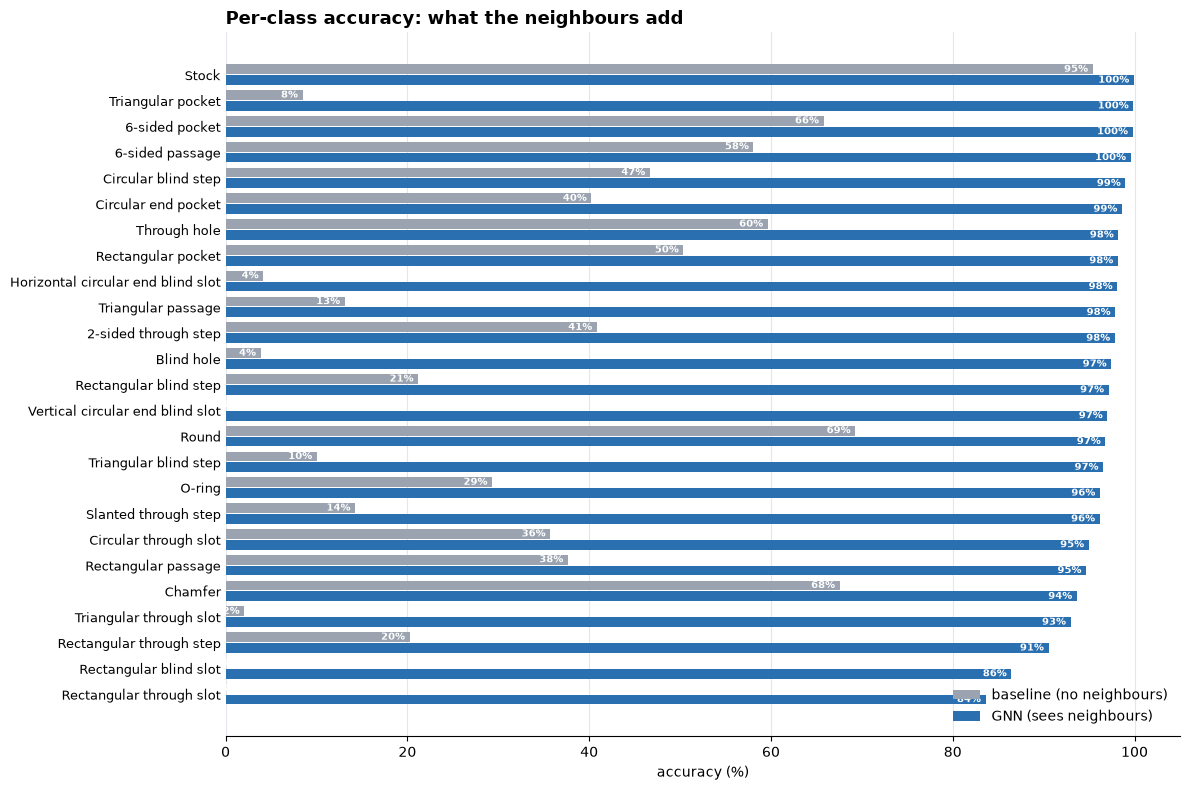


Average across classes — baseline: 31.8%,  GNN: 96.0%


In [4]:
tp_mlp = cm_mlp.diag().float()
tp_gnn = cm_gnn.diag().float()
n_true = cm_gnn.sum(1).float()

acc_mlp = (100 * tp_mlp / n_true.clamp(min=1)).numpy()
acc_gnn = (100 * tp_gnn / n_true.clamp(min=1)).numpy()
order = np.argsort(acc_gnn)

fig, ax = plt.subplots(figsize=(12, 8), facecolor="white")
y_pos = np.arange(K)
h = 0.38

ax.barh(y_pos + h/2 + 0.02, acc_mlp[order], h, label="baseline (no neighbours)", color="#9aa3af")
ax.barh(y_pos - h/2 - 0.02, acc_gnn[order], h, label="GNN (sees neighbours)", color="#2a6fb0")

for y, (b, g) in enumerate(zip(acc_mlp[order], acc_gnn[order])):
    ax.text(max(b, 1) - 0.5, y + h/2 + 0.02, f"{b:.0f}%", va="center", ha="right", fontsize=7, color="white", fontweight="bold")
    ax.text(max(g, 1) - 0.5, y - h/2 - 0.02, f"{g:.0f}%", va="center", ha="right", fontsize=7, color="white", fontweight="bold")

ax.set_xlim(0, 105)
ax.set_yticks(y_pos)
ax.set_yticklabels([LABELS[i] for i in order], fontsize=9)
ax.set_xlabel("accuracy (%)")
ax.set_title("Per-class accuracy: what the neighbours add", loc="left", fontsize=13, fontweight="bold")
ax.legend(frameon=False, loc="lower right", fontsize=10)
ax.grid(axis="x", color="#e3e6ea", linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout(); plt.show()

print(f"\nAverage across classes — baseline: {acc_mlp.mean():.1f}%,  GNN: {acc_gnn.mean():.1f}%")

## 3. Confusion matrix
Each row is the **true** class, each column is what the GNN **predicted**. Colour shows the share of that row (darker = more faces went there).
A perfect model has a dark diagonal and nothing else. Numbers on the diagonal show the class accuracy; numbers off the diagonal show the mistake percentage.

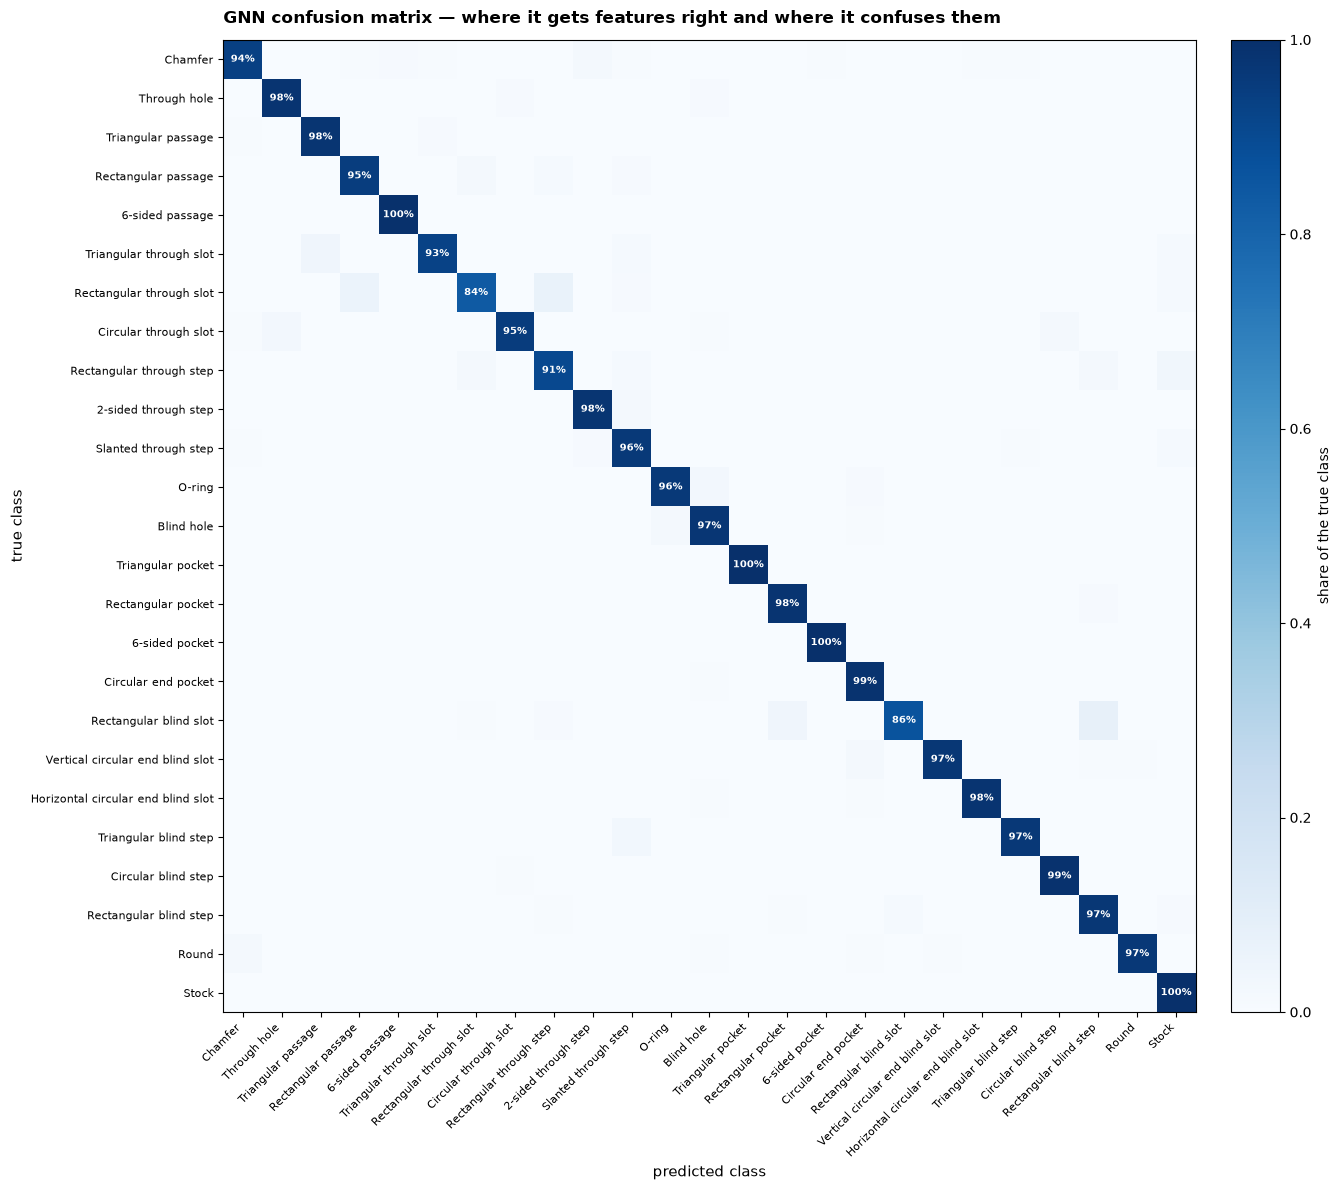

In [5]:
row_share = cm_gnn.float() / cm_gnn.sum(1, keepdim=True).clamp(min=1)

fig, ax = plt.subplots(figsize=(14, 12), facecolor="white")
im = ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(K))
ax.set_yticks(range(K))
ax.set_xticklabels(LABELS, fontsize=8, rotation=45, ha="right")
ax.set_yticklabels(LABELS, fontsize=8)
ax.set_xlabel("predicted class", fontsize=11)
ax.set_ylabel("true class", fontsize=11)

# show accuracy on the diagonal only — no off-diagonal numbers
for i in range(K):
    pct = 100 * row_share[i, i].item()
    colour = "white" if pct > 50 else "#1f2a37"
    ax.text(i, i, f"{pct:.0f}%", ha="center", va="center", fontsize=7, color=colour, fontweight="bold")

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="share of the true class")
ax.set_title("GNN confusion matrix — where it gets features right and where it confuses them",
             loc="left", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 4. Accuracy and IoU for each class
**Accuracy** = of the faces that truly belong to the class, how many were found. **IoU** also counts faces wrongly given this class, so it is stricter.
Classes are sorted from worst to best.

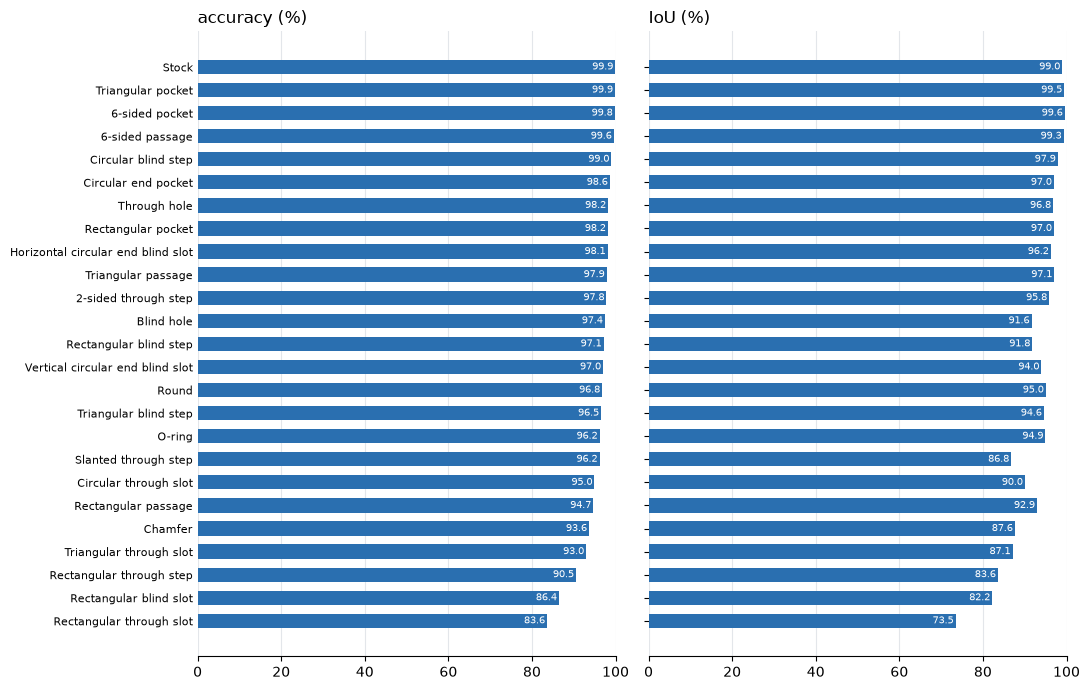

In [6]:
tp = cm_gnn.diag().float()
n_true = cm_gnn.sum(1).float()
acc_c = (tp / n_true.clamp(min=1)).numpy()
iou_c = (tp / (n_true + cm_gnn.sum(0).float() - tp).clamp(min=1)).numpy()
order = np.argsort(acc_c)

fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True, facecolor="white")
for ax, vals, title in zip(axes, (acc_c, iou_c), ("accuracy (%)", "IoU (%)")):
    vals = 100 * vals
    ax.barh(range(K), vals[order], color="#2a6fb0", height=0.62)
    ax.set_xlim(0, 100)
    ax.set_title(title, loc="left")
    ax.grid(axis="x", color="#e3e6ea", linewidth=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    for y, v in enumerate(vals[order]):
        ax.text(v - 0.5, y, f"{v:.1f}", va="center", ha="right", fontsize=7, color="white")
axes[0].set_yticks(range(K)); axes[0].set_yticklabels([LABELS[i] for i in order], fontsize=8)
axes[0].tick_params(axis="y", length=0)
plt.tight_layout(); plt.show()

## 5. The most common mistakes

In [7]:
mistakes = cm_gnn.clone(); mistakes.fill_diagonal_(0)
flat = mistakes.flatten()
print(f"{'true class':<36}{'predicted as':<36}{'faces':>7}{'% of true class':>17}")
for idx in flat.argsort(descending=True)[:15]:
    t, p = divmod(idx.item(), K)
    print(f"{LABELS[t]:<36}{LABELS[p]:<36}{flat[idx].item():>7}{100 * flat[idx].item() / cm_gnn[t].sum().item():>16.1f}%")

true class                          predicted as                          faces  % of true class
Rectangular passage                 Rectangular through slot                 56             2.2%
Rectangular blind slot              Rectangular blind step                   48             7.9%
O-ring                              Blind hole                               47             2.6%
Rectangular through slot            Rectangular through step                 42             6.8%
Rectangular passage                 Rectangular through step                 39             1.5%
Rectangular through slot            Rectangular passage                      38             6.2%
Rectangular through step            Stock                                    37             3.2%
Triangular blind step               Slanted through step                     34             2.9%
2-sided through step                Slanted through step                     31             1.7%
Rectangular through step      

## 6. Part viewer
Each **dot is one face** of the part, each **line is a shared edge** (the same graph the GNN reads). The number in a dot is the class id.
Left: the true labels. Right: what the GNN predicted. **Orange dots are wrong predictions.**

In [8]:
WRONG, RIGHT = "#d9480f", "#d5dae1"

def view_part(i, seed=3):
    g, p = test_set[i], gnn_preds[i]
    y = g.y.cpu()
    wrong = (p != y).numpy()
    G = nx.Graph()
    G.add_nodes_from(range(g.num_nodes))
    G.add_edges_from(g.edge_index.cpu().t().tolist())
    pos = nx.spring_layout(G, seed=seed, k=1.4 / max(1, g.num_nodes) ** 0.5)

    fig, axes = plt.subplots(1, 2, figsize=(13, 6), facecolor="white")
    for ax, labels, title in ((axes[0], y, "true labels"), (axes[1], p, "predicted by the GNN")):
        colours = [WRONG if (w and ax is axes[1]) else RIGHT for w in wrong]
        nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9aa3af", width=1.0)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colours, node_size=420, edgecolors="white", linewidths=1.5)
        nx.draw_networkx_labels(G, pos, ax=ax, labels={n: int(labels[n]) for n in G}, font_size=8)
        ax.set_title(title, loc="left"); ax.axis("off")
    fig.suptitle(f"part {i} ({test_files[i]}):  {g.num_nodes} faces, {int(wrong.sum())} wrong, {100 * (1 - wrong.mean()):.0f}% correct", x=0.01, ha="left")
    plt.tight_layout(); plt.show()

    present = sorted(set(y.tolist()) | set(p.tolist()))
    print("class ids in this part:", "; ".join(f"{c} = {LABELS[c]}" for c in present))
    print("STEP file:", os.path.join(ROOT, "step", "test", test_files[i]))

### The parts the GNN gets most wrong
Pick any of these numbers for `view_part`.

In [9]:
worst = np.argsort(part_acc)[:10]
for i in worst:
    print(f"part {i:>4}  {test_files[i]:<14} {100 * part_acc[i]:5.1f}% of {test_set[i].num_nodes} faces correct")

part  886  24281.step      61.5% of 13 faces correct
part 1066  38429.step      64.4% of 45 faces correct
part  123  11963.step      66.7% of 12 faces correct
part 1202  56619.step      68.8% of 16 faces correct
part  296  42492.step      71.1% of 38 faces correct
part 1474  27953.step      71.4% of 35 faces correct
part 1007  35977.step      73.7% of 19 faces correct
part  731  5219.step       73.7% of 38 faces correct
part 1250  2035.step       74.1% of 27 faces correct
part  832  37314.step      75.0% of 36 faces correct


### Look at a part: change the number and re-run this cell

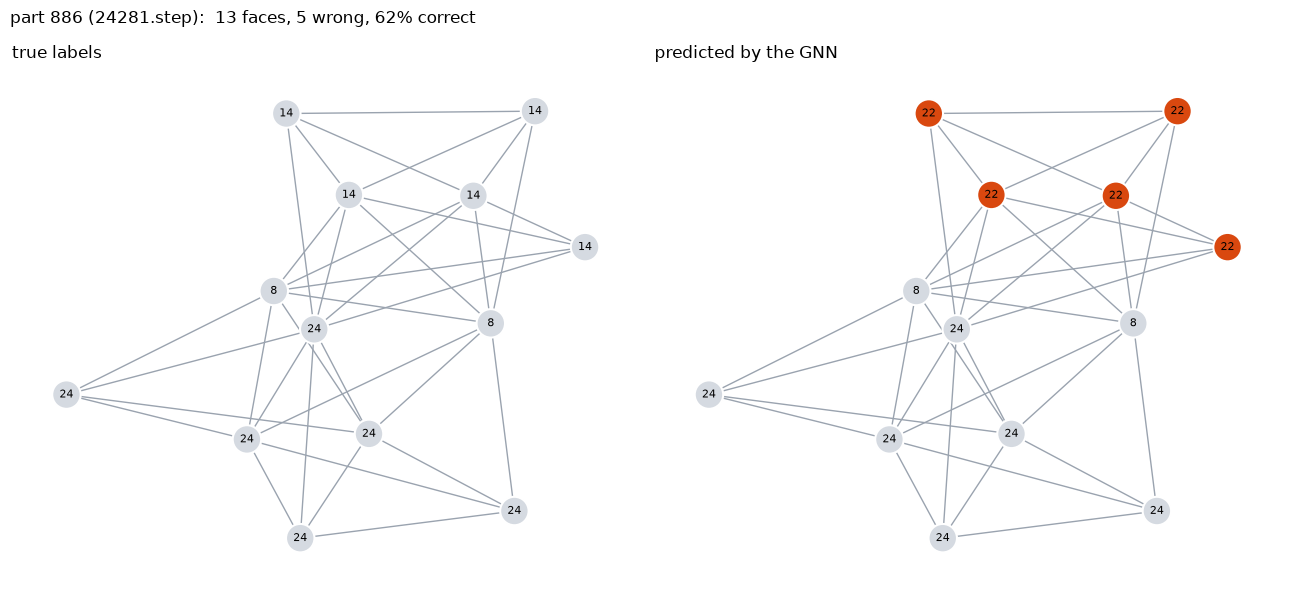

class ids in this part: 8 = Rectangular through step; 14 = Rectangular pocket; 22 = Rectangular blind step; 24 = Stock
STEP file: c:\Users\UDAY\Documents\AnK-Progress\brep_gnn\mfcad\data\MFCAD_dataset\MFCAD++_dataset\step\test\24281.step


In [10]:
view_part(int(worst[0]))     # the worst part; try view_part(0) or any number from 0 to 1499

### A typical part

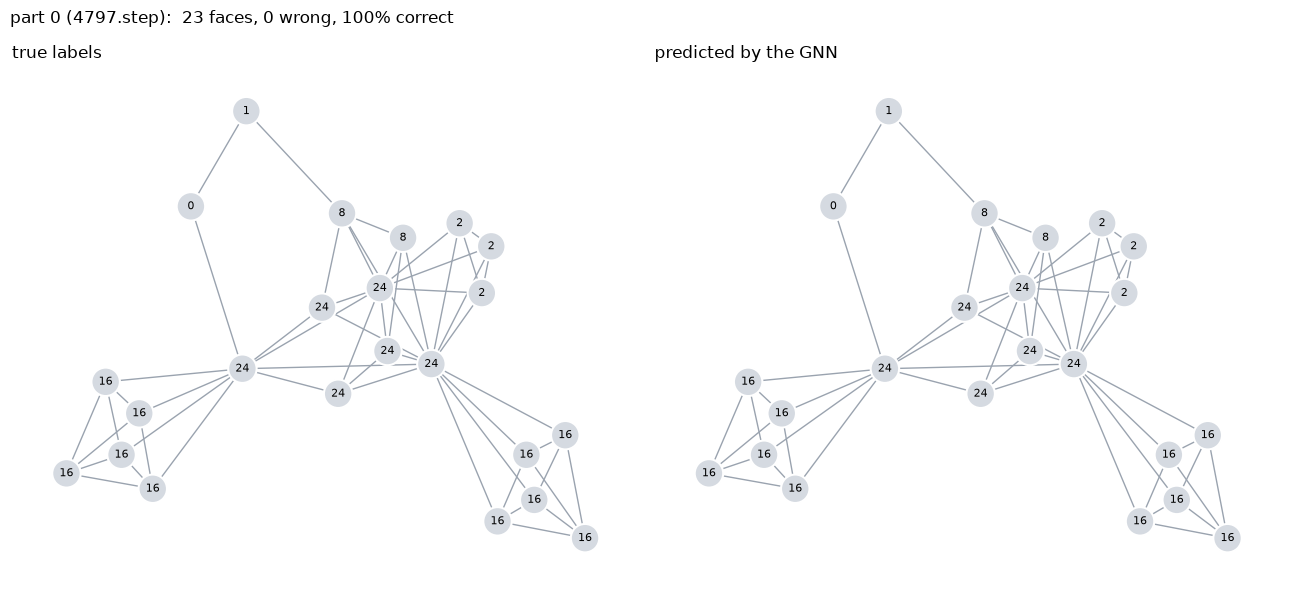

class ids in this part: 0 = Chamfer; 1 = Through hole; 2 = Triangular passage; 8 = Rectangular through step; 16 = Circular end pocket; 24 = Stock
STEP file: c:\Users\UDAY\Documents\AnK-Progress\brep_gnn\mfcad\data\MFCAD_dataset\MFCAD++_dataset\step\test\4797.step


In [11]:
view_part(0)